
================ ECP RELATIVE ERRORS =================

T = 10 °C
Rm RE = 0.0742 %
Lm RE = 0.0485 %
Cm RE = 0.0771 %
Rs RE = 0.1980 %


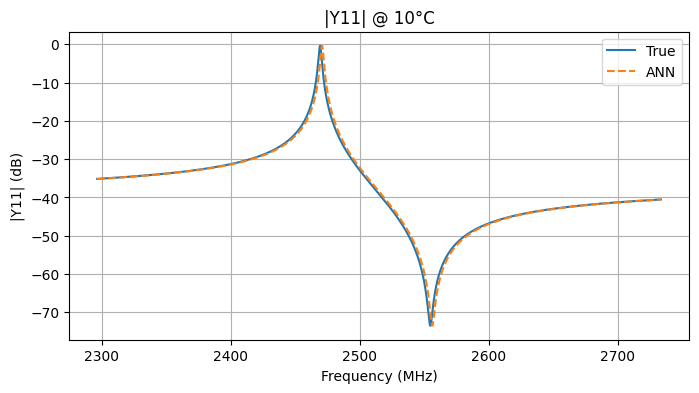


T = 37 °C
Rm RE = 0.5302 %
Lm RE = 0.2272 %
Cm RE = 0.2318 %
Rs RE = 0.0654 %


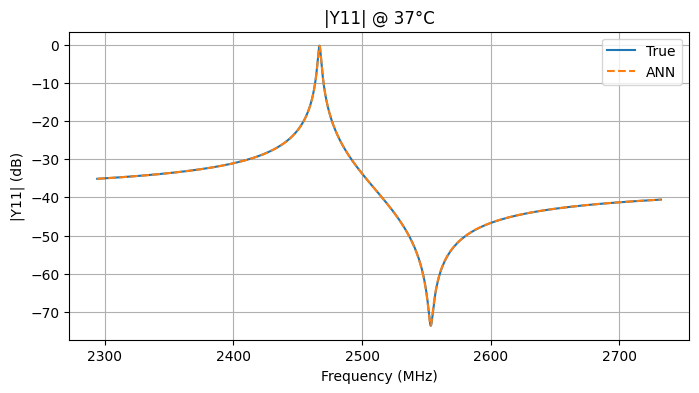


T = 55 °C
Rm RE = 0.5800 %
Lm RE = 0.3927 %
Cm RE = 0.0670 %
Rs RE = 0.1371 %


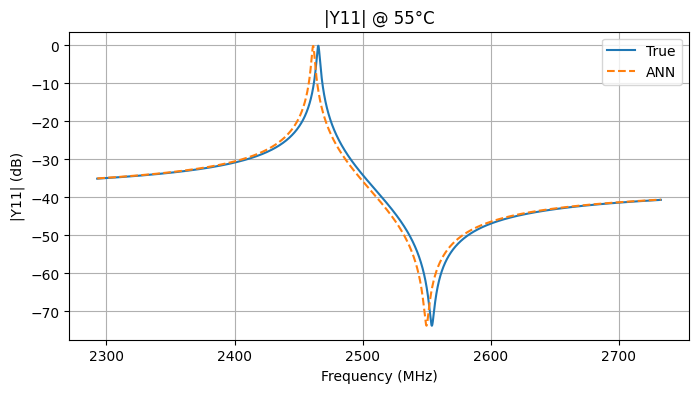


T = 70 °C
Rm RE = 0.1639 %
Lm RE = 0.4957 %
Cm RE = 0.3052 %
Rs RE = 0.0014 %


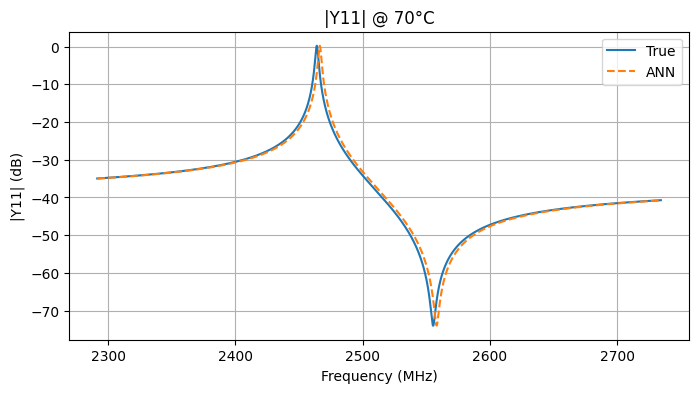


T = 95 °C
Rm RE = 0.1767 %
Lm RE = 0.2434 %
Cm RE = 0.3084 %
Rs RE = 0.1239 %


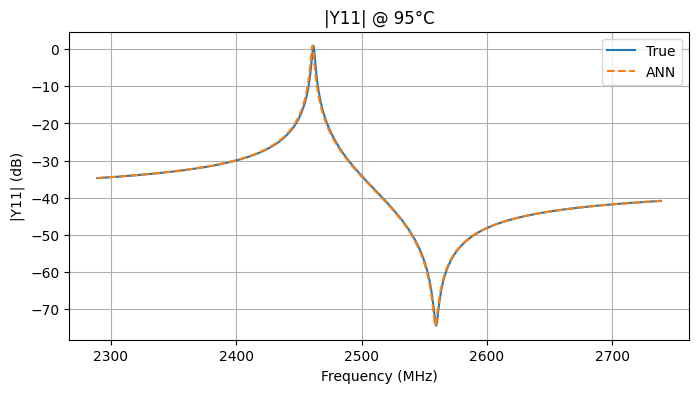

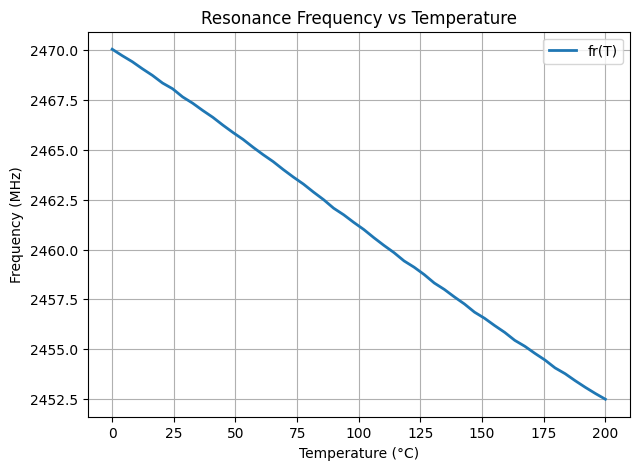

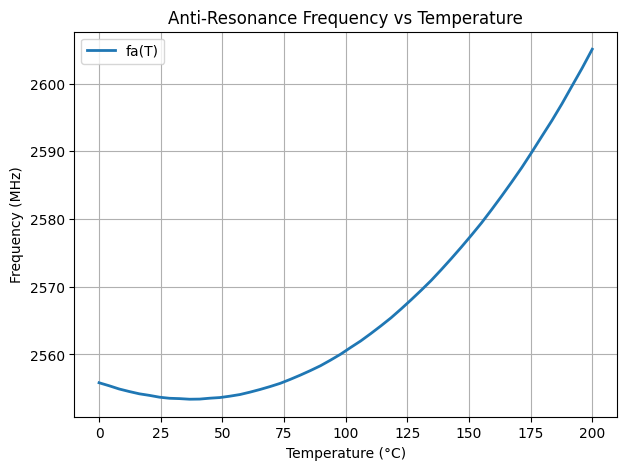

In [ ]:
import os
import random
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

tf.get_logger().setLevel("ERROR")

# ======================================================
# FIXED SEEDS FOR FULL REPRODUCIBILITY
# ======================================================
SEED = 0

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)

np.random.seed(SEED)

tf.keras.utils.set_random_seed(SEED)

tf.config.experimental.enable_op_determinism()

# ======================================================
# CONSTANTS
# ======================================================
PI = math.pi

# ======================================================
# FIXED STRUCTURAL PARAMETERS
# ======================================================
Cs = 7.95e-13

R0 = 0.25

# ======================================================
# BASE PARAMETERS
# ======================================================
fr0 = 2.468e9

Qs0 = 887

Qp0 = 3770

k20 = 0.08

# ======================================================
# THERMAL MODEL PARAMETERS
# ======================================================
TCF1 = -35e-6
TCF2 = -4e-8
TCF3 = 2e-10

alpha1 = 5e-4
alpha2 = 2e-5

beta1 = 0.02
beta2 = 1e-4

gamma1 = 0.015
gamma2 = 8e-5

# ======================================================
# TRUE NONLINEAR THERMAL MBVD MODEL
# ======================================================
def true_ECPs(T):

    dT = T - 25.0

    # --------------------------------------------------
    # RESONANCE FREQUENCY
    # --------------------------------------------------
    fr = fr0 * (

        1
        + TCF1*dT
        + TCF2*dT**2
        + TCF3*dT**3

    )

    # --------------------------------------------------
    # ELECTROMECHANICAL COUPLING
    # --------------------------------------------------
    k2 = k20 * (

        1
        + alpha1*dT
        + alpha2*dT**2

    )

    # --------------------------------------------------
    # SERIES QUALITY FACTOR
    # --------------------------------------------------
    Qs = Qs0 * np.exp(

        -beta1*dT/100
        + beta2*dT**2/10000

    )

    # --------------------------------------------------
    # PARALLEL QUALITY FACTOR
    # --------------------------------------------------
    Qp = Qp0 * np.exp(

        -gamma1*dT/100
        + gamma2*dT**2/10000

    )

    # --------------------------------------------------
    # ANTI-RESONANCE FREQUENCY
    # --------------------------------------------------
    fa = (

        2*fr

        /

        (
            1
            +
            np.sqrt(
                1 - (16*k2)/(PI**2)
            )
        )

    )

    wr = 2*np.pi*fr

    wa = 2*np.pi*fa

    # --------------------------------------------------
    # MOTIONAL CAPACITANCE
    # --------------------------------------------------
    Cm = Cs * (

        (fa/fr)**2 - 1

    )

    # --------------------------------------------------
    # MOTIONAL INDUCTANCE
    # --------------------------------------------------
    Lm = 1 / (

        (2*np.pi*fr)**2 * Cm

    )

    # --------------------------------------------------
    # MOTIONAL RESISTANCE
    # --------------------------------------------------
    Rm = (

        wr * (Lm/Qs)

    ) - R0

    # --------------------------------------------------
    # STATIC BRANCH LOSS
    # --------------------------------------------------
    Rs = (

        wa * (Lm/Qp)

    ) - Rm

    return (

        np.maximum(Rm,1e-6),
        np.maximum(Lm,1e-18),
        np.maximum(Cm,1e-18),
        np.maximum(Rs,1e-6)

    )

# ======================================================
# EXTRACTION NOISE
# ======================================================
def add_noise(Rm,Lm,Cm,Rs):

    noise = np.random.uniform(0.001,0.003)

    Rm *= (1 + noise*np.random.randn())

    Lm *= (1 + noise*np.random.randn())

    Cm *= (1 + noise*np.random.randn())

    Rs *= (1 + noise*np.random.randn())

    return Rm,Lm,Cm,Rs

# ======================================================
# TRAINING DATA
# INPUT  : TEMPERATURE
# OUTPUT : ECPs (Rm,Lm,Cm,Rs)
# ======================================================
train_temps = [0,25,60,85,100]

X_train=[]
Y_train=[]

for T in train_temps:

    Rm,Lm,Cm,Rs = true_ECPs(T)

    Rm,Lm,Cm,Rs = add_noise(

        Rm,
        Lm,
        Cm,
        Rs

    )

    # ---------------------------------------------
    # INPUT
    # ---------------------------------------------
    X_train.append([T])

    # ---------------------------------------------
    # OUTPUT ECPs
    # ---------------------------------------------
    Y_train.append([

        np.log(Rm),
        np.log(Lm),
        np.log(Cm),
        np.log(Rs)

    ])

X_train=np.array(X_train,np.float32)

Y_train=np.array(Y_train,np.float32)

# ======================================================
# NORMALIZATION
# ======================================================
Xm = X_train.mean(0)

Xs = X_train.std(0)

Ym = Y_train.mean(0)

Ys = Y_train.std(0)

Xs = np.maximum(Xs,1e-6)

Ys = np.maximum(Ys,1e-6)

Xn = (X_train-Xm)/Xs

Yn = (Y_train-Ym)/Ys

# ======================================================
# ANN MODEL
# ======================================================
tf.keras.backend.clear_session()

tf.keras.utils.set_random_seed(SEED)

model = tf.keras.Sequential([

    tf.keras.layers.Input((1,)),

    tf.keras.layers.Dense(
        64,
        activation="tanh",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    ),

    tf.keras.layers.Dense(
        64,
        activation="tanh",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    ),

    tf.keras.layers.Dense(
        32,
        activation="tanh",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    ),

    # OUTPUT:
    # Rm, Lm, Cm, Rs
    tf.keras.layers.Dense(4)

])

model.compile(

    optimizer=tf.keras.optimizers.Adam(1e-3),

    loss="mse"

)

earlystop = tf.keras.callbacks.EarlyStopping(

    monitor="loss",

    patience=50,

    restore_best_weights=True

)

model.fit(

    Xn,
    Yn,

    epochs=1000,

    shuffle=False,

    verbose=0,

    callbacks=[earlystop]

)

# ======================================================
# NONLINEAR MBVD SIMULATION
# ======================================================
def simulate_Y11(Rm,Lm,Cm,Rs,T):

    dT = T - 25

    # --------------------------------------------------
    # RECONSTRUCT fr
    # --------------------------------------------------
    fr = fr0 * (

        1
        + TCF1*dT
        + TCF2*dT**2
        + TCF3*dT**3

    )

    # --------------------------------------------------
    # RECONSTRUCT k2
    # --------------------------------------------------
    k2 = k20 * (

        1
        + alpha1*dT
        + alpha2*dT**2

    )

    # --------------------------------------------------
    # RECONSTRUCT fa
    # --------------------------------------------------
    fa = (

        2*fr

        /

        (
            1
            +
            np.sqrt(
                1 - (16*k2)/(PI**2)
            )
        )

    )

    # --------------------------------------------------
    # FREQUENCY SWEEP
    # --------------------------------------------------
    f = np.linspace(

        fr*0.93,
        fa*1.07,
        6000

    )

    w = 2*np.pi*f

    # --------------------------------------------------
    # STATIC BRANCH
    # --------------------------------------------------
    Zs = (

        R0
        +
        1/(1j*w*Cs)

    )

    # --------------------------------------------------
    # MOTIONAL BRANCH
    # --------------------------------------------------
    Zm = (

        Rm
        +
        1j*w*Lm
        +
        1/(1j*w*Cm)

    )

    # --------------------------------------------------
    # PARALLEL NETWORK
    # --------------------------------------------------
    Zp = 1/(1/Zs + 1/Zm)

    # --------------------------------------------------
    # TOTAL IMPEDANCE
    # --------------------------------------------------
    Ztotal = (

        Rs
        +
        Zp

    )

    # --------------------------------------------------
    # ADMITTANCE
    # --------------------------------------------------
    Y11 = np.abs(

        1/Ztotal

    )

    return f,Y11

# ======================================================
# TEST TEMPERATURES
# ======================================================
test_temps = [10,37,55,70,95]

print("\n================ ECP RELATIVE ERRORS =================")

for T in test_temps:

    # --------------------------------------------------
    # TRUE ECPs
    # --------------------------------------------------
    Rm_t,Lm_t,Cm_t,Rs_t = true_ECPs(T)

    # --------------------------------------------------
    # ANN PREDICTION
    # --------------------------------------------------
    Xt = (

        np.array([[T]],dtype=np.float32)

        - Xm

    ) / Xs

    yp = model.predict(

        Xt,
        verbose=0

    )[0]

    yp = yp*Ys + Ym

    Rm_p = np.exp(yp[0])

    Lm_p = np.exp(yp[1])

    Cm_p = np.exp(yp[2])

    Rs_p = np.exp(yp[3])

    # --------------------------------------------------
    # RELATIVE ERRORS
    # --------------------------------------------------
    RE_Rm = abs((Rm_p-Rm_t)/Rm_t)*100

    RE_Lm = abs((Lm_p-Lm_t)/Lm_t)*100

    RE_Cm = abs((Cm_p-Cm_t)/Cm_t)*100

    RE_Rs = abs((Rs_p-Rs_t)/Rs_t)*100

    print(f"\nT = {T} °C")

    print(f"Rm RE = {RE_Rm:.4f} %")

    print(f"Lm RE = {RE_Lm:.4f} %")

    print(f"Cm RE = {RE_Cm:.4f} %")

    print(f"Rs RE = {RE_Rs:.4f} %")

    # --------------------------------------------------
    # TRUE RESPONSE
    # --------------------------------------------------
    f,Y_true = simulate_Y11(

        Rm_t,
        Lm_t,
        Cm_t,
        Rs_t,
        T

    )

    # --------------------------------------------------
    # ANN RESPONSE
    # --------------------------------------------------
    _,Y_ann = simulate_Y11(

        Rm_p,
        Lm_p,
        Cm_p,
        Rs_p,
        T

    )

    # --------------------------------------------------
    # PLOT
    # --------------------------------------------------
    plt.figure(figsize=(8,4))

    plt.plot(

        f/1e6,
        20*np.log10(Y_true),

        label="True"

    )

    plt.plot(

        f/1e6,
        20*np.log10(Y_ann),

        "--",

        label="ANN"

    )

    plt.title(f"|Y11| @ {T}°C")

    plt.xlabel("Frequency (MHz)")

    plt.ylabel("|Y11| (dB)")

    plt.grid(True)

    plt.legend()

    plt.show()

# ======================================================
# TEMPERATURE SWEEP
# ======================================================
T_dense = np.linspace(0,200,50)

fr_list=[]
fa_list=[]

for T in T_dense:

    Rm,Lm,Cm,Rs = true_ECPs(T)

    f,Y = simulate_Y11(

        Rm,
        Lm,
        Cm,
        Rs,
        T

    )

    fr = f[np.argmax(Y)]

    fa = f[np.argmin(Y)]

    fr_list.append(fr/1e6)

    fa_list.append(fa/1e6)

# ======================================================
# RESONANCE PLOT
# ======================================================
plt.figure(figsize=(7,5))

plt.plot(

    T_dense,
    fr_list,

    linewidth=2,

    label="fr(T)"

)

plt.xlabel("Temperature (°C)")

plt.ylabel("Frequency (MHz)")

plt.title("Resonance Frequency vs Temperature")

plt.grid(True)

plt.legend()

plt.show()

# ======================================================
# ANTI-RESONANCE PLOT
# ======================================================
plt.figure(figsize=(7,5))

plt.plot(

    T_dense,
    fa_list,

    linewidth=2,

    label="fa(T)"

)

plt.xlabel("Temperature (°C)")

plt.ylabel("Frequency (MHz)")

plt.title("Anti-Resonance Frequency vs Temperature")

plt.grid(True)

plt.legend()

plt.show()